# Practical 20: K-Nearest Neighbors Regression

**Aim:** To predict final examination scores using KNN Regression, compare different values of K, and plot actual versus predicted performance.

**Kaggle Dataset:** [Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors)

Download `StudentPerformanceFactors.csv` and keep it in the same folder as this notebook.

**Selected features:** `Hours_Studied`, `Attendance`, and `Previous_Scores`. This dataset does not contain a separate assignment-marks column, so Previous_Scores is used as the third academic feature.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load dataset
data = pd.read_csv('StudentPerformanceFactors.csv')
data.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
# Select input and output
data = data[['Hours_Studied', 'Attendance', 'Previous_Scores', 'Exam_Score']]
data = data.dropna()

X = data[['Hours_Studied', 'Attendance', 'Previous_Scores']].values
y = data['Exam_Score'].values

## Split the data

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Feature scaling

In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# Apply KNN Regression for different K values

In [6]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error

k_list = []
score_list = []

for k in range(1, 11):
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = r2_score(y_test, y_pred)
    k_list.append(k)
    score_list.append(score)
    print('R2 Score for K =', k, ':', score)

R2 Score for K = 1 : 0.1124104787796455
R2 Score for K = 2 : 0.4070205241009017
R2 Score for K = 3 : 0.4864522169382506
R2 Score for K = 4 : 0.530147080551692
R2 Score for K = 5 : 0.5479383378319956
R2 Score for K = 6 : 0.5556909067291746
R2 Score for K = 7 : 0.5688641207927088
R2 Score for K = 8 : 0.5773476006471111
R2 Score for K = 9 : 0.5799953547106598
R2 Score for K = 10 : 0.5815978131157999


In [7]:
# Find best K value
best_k = k_list[score_list.index(max(score_list))]
print('Best K value:', best_k)

Best K value: 10


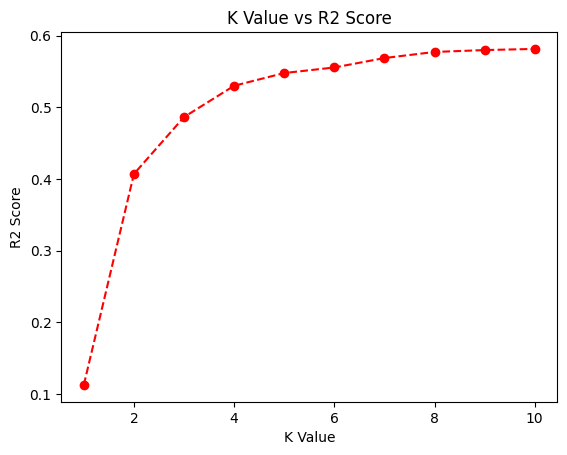

In [8]:
# Plot K value vs R2 score
plt.plot(k_list, score_list, 'r--o')
plt.xlabel('K Value')
plt.ylabel('R2 Score')
plt.title('K Value vs R2 Score')
plt.show()

# Actual vs Predicted performance

Mean Squared Error: 5.914145234493192
R2 Score: 0.5815978131157999


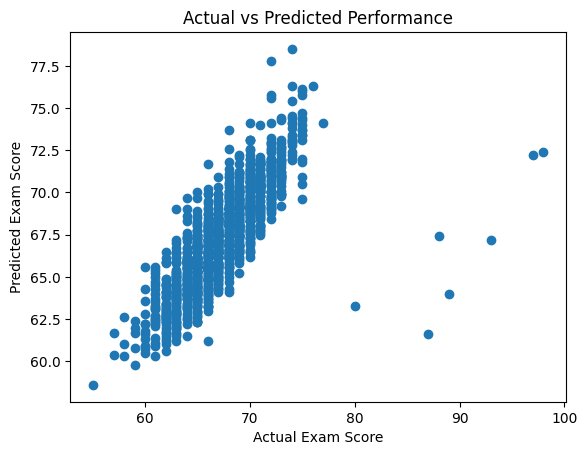

In [9]:
model = KNeighborsRegressor(n_neighbors=best_k)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Mean Squared Error:', mean_squared_error(y_test, y_pred))
print('R2 Score:', r2_score(y_test, y_pred))

plt.scatter(y_test, y_pred)
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Performance')
plt.show()

## Conclusion

KNN Regression was implemented on the Student Performance Factors dataset. Different K values were compared using the R2 score, and actual versus predicted exam scores were plotted.